In [1]:
# ! python -m pip install "numpy==1.23.5" "matplotlib==3.7.5" "ipython==8.18.1" "ipympl==0.9.4"

In [2]:
%matplotlib widget

In [1]:
import numpy as np
from dezero import Variable
import dezero.functions as F

# 追加ライブラリ
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [3]:
N = 100


x_data = np.random.rand(N)
y_data = np.sin(2 * np.pi * x_data) + np.random.rand(N)
print(np.round(x_data[:10], 3))
print(np.round(y_data[:10], 3))

[0.128 0.864 0.951 0.735 0.144 0.05  0.919 0.114 0.536 0.75 ]
[ 0.787 -0.597 -0.11  -0.706  1.357  1.012  0.048  1.296  0.277 -0.994]


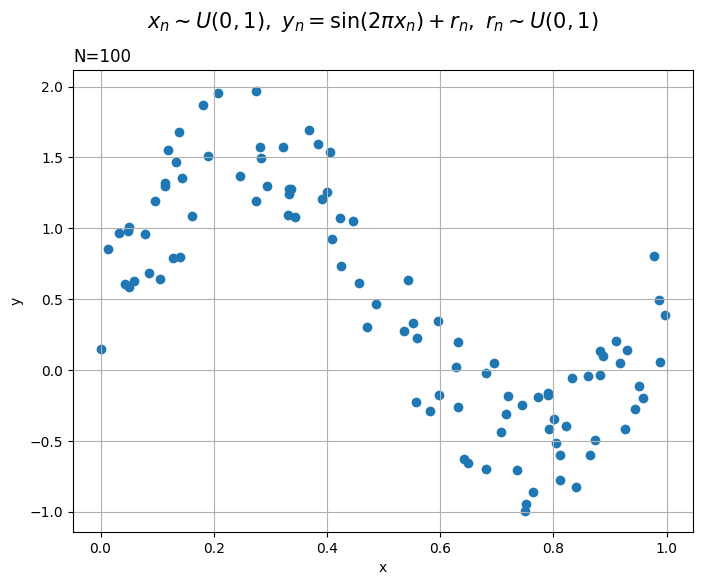

In [4]:
plt.figure(figsize=(8, 6), facecolor='white')
plt.scatter(x_data, y_data)
plt.xlabel('x')
plt.ylabel('y')
plt.title('N=' + str(N), loc='left')
plt.suptitle('$x_n \sim U(0, 1),\ y_n = \sin(2 \pi x_n) + r_n,\ r_n \sim U(0, 1)$', fontsize=15)
plt.grid()
plt.show()

In [5]:
x_line = np.linspace(-5, 5, num=251)
print(x_line[:10])

[-5.   -4.96 -4.92 -4.88 -4.84 -4.8  -4.76 -4.72 -4.68 -4.64]


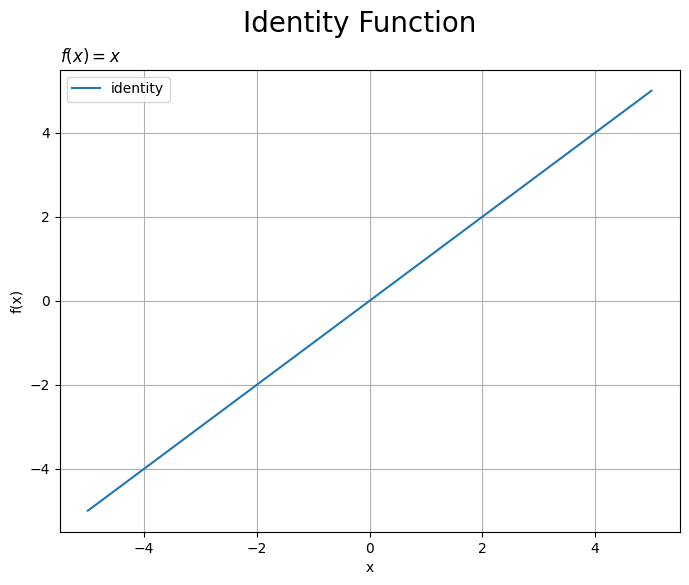

In [6]:
plt.figure(figsize=(8, 6), facecolor='white')
plt.plot(x_line, x_line, label='identity')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.suptitle('Identity Function', fontsize=20)
plt.title('$f(x) = x$', loc='left')
plt.legend()
plt.grid()
plt.show()

In [7]:
W = np.array([[-6.0]])
b = np.array([10.0])

# 선형 변환 계산
y_linear = F.linear(x_line.reshape((-1, 1)), W, b).data.flatten()
print(np.round(y_linear[:10], 3))

[40.   39.76 39.52 39.28 39.04 38.8  38.56 38.32 38.08 37.84]


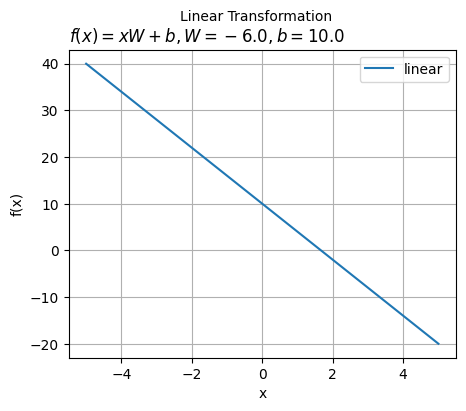

In [11]:
# 파레마터 표시
param_label = 'f(x) = x W + b'
param_label += ', W='+str(W.item()) + ', b='+str(b.item())

#　선형 변환 그래프 작성
plt.figure(figsize=(5, 4), facecolor='white')
plt.plot(x_line, y_linear, label='linear')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.suptitle('Linear Transformation', fontsize=10)
plt.title('$'+param_label+'$', loc='left')
plt.legend()
plt.grid()
plt.show()

In [13]:
# 활성화 함수 계산
y_sigmoid = F.sigmoid(x_line).data
y_relu = F.relu(x_line).data
y_tanh = F.tanh(x_line).data
print(np.round(y_sigmoid[:10], 3))
print(y_relu[:10])
print(np.round(y_tanh[:10], 3))

[0.007 0.007 0.007 0.008 0.008 0.008 0.008 0.009 0.009 0.01 ]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[-1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


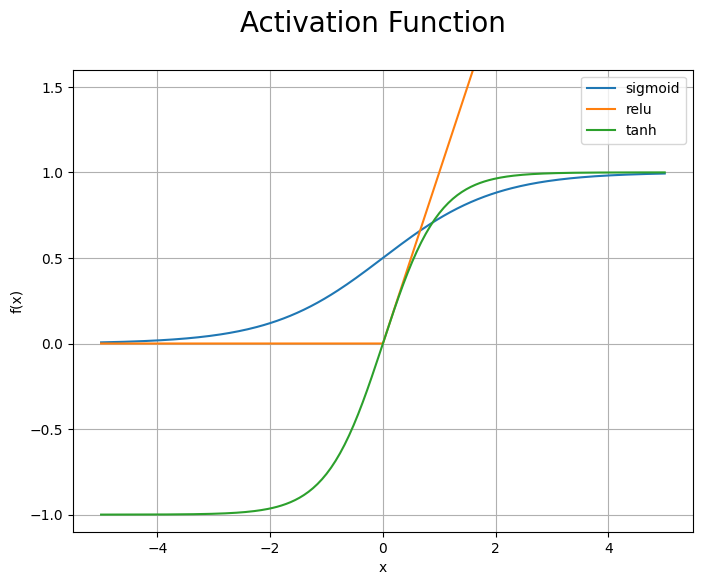

In [14]:
# 활성화 함수 그래프 작성
plt.figure(figsize=(8, 6), facecolor='white')
plt.plot(x_line, y_sigmoid, label='sigmoid')
plt.plot(x_line, y_relu, label='relu')
plt.plot(x_line, y_tanh, label='tanh')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.suptitle('Activation Function', fontsize=20)
plt.legend()
plt.grid()
plt.ylim(-1.1, 1.6)
plt.show()

In [15]:
# 2층 신경망 계산
def predict(x, W1, b1, W2, b2):
    # 입력층 계산 
    y = F.linear(x, W1, b1)
    y = F.sigmoid(y)
    
    # 출력층 게산
    y = F.linear(y, W2, b2)
    return y

In [16]:
# 반복 횟수 지정
iters = 10000

# 학습률 지정
lr = 0.2

# 입력층·은닉층·출력층의 크기 지정
I = 1
H = 10
O = 1

# 데이터셋을 Variable로 변환
x = Variable(x_data.reshape((N, 1)))
y = Variable(y_data.reshape((N, 1)))

# 파라미터 초기화
W1 = Variable(0.01 * np.random.randn(I, H))
b1 = Variable(np.zeros(H))
W2 = Variable(0.01 * np.random.randn(H, O))
b2 = Variable(np.zeros(O))

# 학습 과정 확인용 리스트 초기화
trace_loss = []
trace_W1 = [W1.data[0].copy()]
trace_b1 = [b1.data.copy()]
trace_W2 = [W2.data[:, 0].copy()]
trace_b2 = [b2.data.copy()]

# 반복 학습
for i in range(iters):
    # 신경망의 예측값 계산
    y_pred = predict(x, W1, b1, W2, b2)

    # 손실 계산
    loss = F.mean_squared_error(y, y_pred)

    # 기울기 초기화
    W1.cleargrad()
    b1.cleargrad()
    W2.cleargrad()
    b2.cleargrad()

    # 기울기 역전파 계산
    loss.backward()

    # 경사 하강법으로 파라미터 업데이트
    W1.data -= lr * W1.grad.data
    b1.data -= lr * b1.grad.data
    W2.data -= lr * W2.grad.data
    b2.data -= lr * b2.grad.data

    # 업데이트된 값 저장
    trace_loss.append(loss.data)
    trace_W1.append(W1.data[0].copy())
    trace_b1.append(b1.data.copy())
    trace_W2.append(W2.data[:, 0].copy())
    trace_b2.append(b2.data.copy())

    # 일정 반복마다 손실 출력
    if (i + 1) % 500 == 0:
        print('iter ' + str(i + 1) + ': loss=' + str(loss.data))

iter 500: loss=0.27977484760016696
iter 1000: loss=0.2773025645869999
iter 1500: loss=0.27480500907443167
iter 2000: loss=0.27129705711742247
iter 2500: loss=0.2651948402621115
iter 3000: loss=0.25422728409472833
iter 3500: loss=0.23759143423655082
iter 4000: loss=0.21622517730961044
iter 4500: loss=0.1856176910882281
iter 5000: loss=0.14186403307994838
iter 5500: loss=0.10659540637346182
iter 6000: loss=0.09309381461668804
iter 6500: loss=0.08990242840366354
iter 7000: loss=0.0891357693739267
iter 7500: loss=0.08879123821506844
iter 8000: loss=0.08852177972049137
iter 8500: loss=0.08827562036108129
iter 9000: loss=0.08804481073787963
iter 9500: loss=0.08782739487304467
iter 10000: loss=0.08762225846884912


In [17]:
# 예측값 계산
y_pred = predict(x, W1, b1, W2, b2)
print(np.round(y_pred.data[:10].flatten(), 3))

# 손실 계산
last_loss = F.mean_squared_error(y, y_pred).data
print(last_loss)

[ 1.176 -0.22   0.026 -0.437  1.236  0.831 -0.069  1.118  0.229 -0.429]
0.08762185986085916


In [19]:
# 회귀 곡선 계산
x_line = np.linspace(0, 1, num=101)
y_line = predict(x_line.reshape((-1, 1)), W1, b1, W2, b2).data.flatten()
print(np.round(x_line[:10], 3))
print(np.round(y_line[:10], 3))

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09]
[0.591 0.64  0.689 0.737 0.785 0.833 0.879 0.925 0.971 1.015]


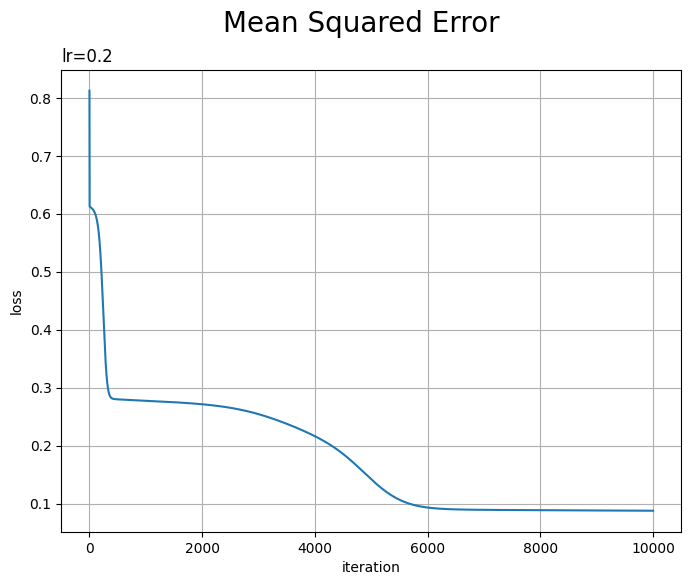

In [20]:
# 손실함수의 추이 그래프 작성
plt.figure(figsize=(8, 6), facecolor='white')
plt.plot(np.arange(iters+1), trace_loss+[last_loss])
plt.xlabel('iteration')
plt.ylabel('loss')
plt.suptitle('Mean Squared Error', fontsize=20)
plt.title('lr='+str(lr), loc='left')
plt.grid()
plt.show()

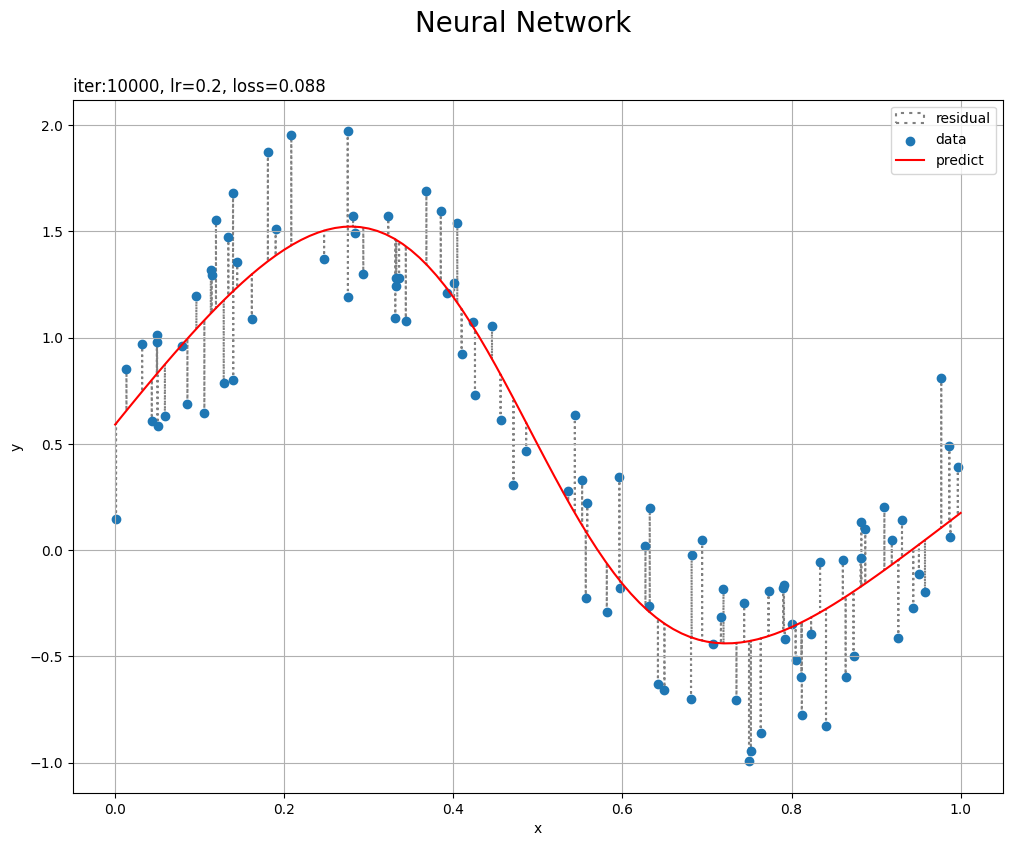

In [21]:
# 잔차 계산
y_residual = y_pred.data.flatten() - y_data

# 매개변수 레이블 생성
param_label = 'iter:' + str(iters)
param_label += ', lr=' + str(lr)
param_label += ', loss='+str(np.round(last_loss, 3))

# 그래프 그리기
plt.figure(figsize=(12, 9), facecolor='white')
plt.quiver(x_data, y_data, np.repeat(0, N), y_residual, 
           scale_units='xy', scale=1, units='dots', width=0.1, headwidth=0.1, 
           fc='none', ec='gray', linewidth=1.5, linestyle=':', label='residual') # 잔차
plt.scatter(x_data, y_data, label='data') # 데이터
plt.plot(x_line, y_line, color='red', label='predict') # 예측 곡선
plt.xlabel('x')
plt.ylabel('y')
plt.suptitle('Neural Network', fontsize=20)
plt.title(param_label, loc='left')
plt.grid()
plt.legend()
plt.show()